<a href="https://colab.research.google.com/github/shivamkumar359/03-rd-SEM--ASSIGNMENTS/blob/main/ML_W_10_Q1_ASSIGNMENT_1_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TASK 1: K-MEANS CLUSTERING

Original Dataset:


,Point,X,Y
0,P1,1,1
1,P2,2,2
2,P3,5,5
3,P4,6,6
4,P5,8,9



Initial Centroids:
Centroid 1: [1. 2.]
Centroid 2: [7. 8.]

ITERATION 1

Centroids Used:
C1 = [1. 2.]
C2 = [7. 8.]

Distance Calculations and Cluster Assignments:


,Point,X,Y,Distance to C1,Distance to C2,Assigned Cluster
0,P1,1,1,1.0000,9.2195,Cluster 1
1,P2,2,2,1.0000,7.8102,Cluster 1
2,P3,5,5,5.0000,3.6056,Cluster 2
3,P4,6,6,6.4031,2.2361,Cluster 2
4,P5,8,9,9.8995,1.4142,Cluster 2



Updated Centroids:
C1 = [1.5 1.5]
Number of points in Cluster 1: 2
Mean X = 1.5000
Mean Y = 1.5000

C2 = [6.3333 6.6667]
Number of points in Cluster 2: 3
Mean X = 6.3333
Mean Y = 6.6667


ITERATION 2

Centroids Used:
C1 = [1.5 1.5]
C2 = [6.33333333 6.66666667]

Distance Calculations and Cluster Assignments:


,Point,X,Y,Distance to C1,Distance to C2,Assigned Cluster
0,P1,1,1,0.7071,7.7817,Cluster 1
1,P2,2,2,0.7071,6.3683,Cluster 1
2,P3,5,5,4.9497,2.1344,Cluster 2
3,P4,6,6,6.3640,0.7454,Cluster 2
4,P5,8,9,9.9247,2.8674,Cluster 2



Updated Centroids:
C1 = [1.5 1.5]
Number of points in Cluster 1: 2
Mean X = 1.5000
Mean Y = 1.5000

C2 = [6.3333 6.6667]
Number of points in Cluster 2: 3
Mean X = 6.3333
Mean Y = 6.6667


FINAL RESULTS AFTER TWO ITERATIONS

Final Centroid Coordinates:
μ1 = (1.5000, 1.5000)
μ2 = (6.3333, 6.6667)

Final Cluster Assignments:


,Point,Iteration 1,Iteration 2
0,P1,Cluster 1,Cluster 1
1,P2,Cluster 1,Cluster 1
2,P3,Cluster 2,Cluster 2
3,P4,Cluster 2,Cluster 2
4,P5,Cluster 2,Cluster 2


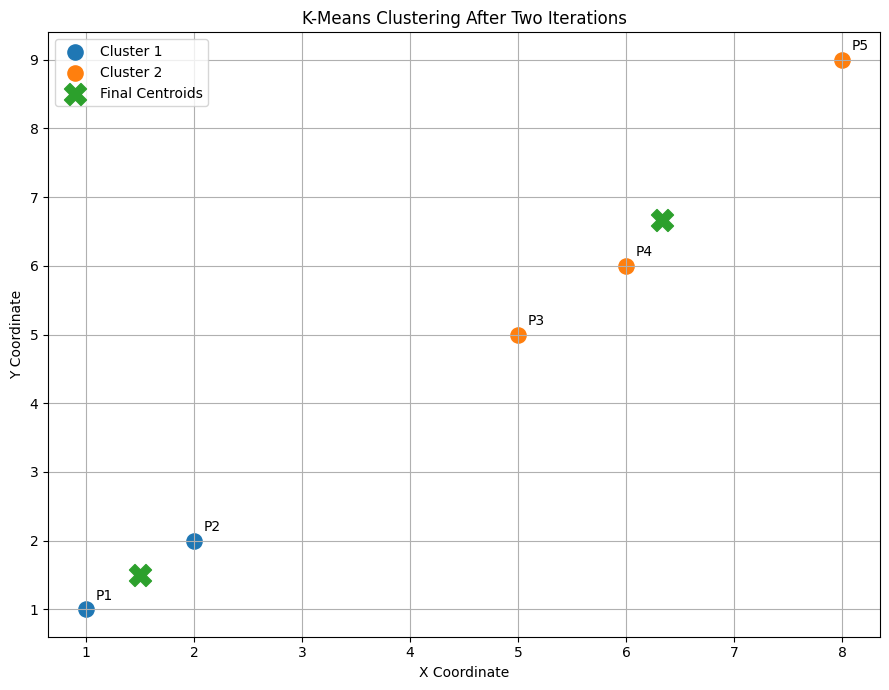


PDF CALCULATION SHEET GENERATED SUCCESSFULLY!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
# ============================================================
# TASK 1: MANUAL K-MEANS CLUSTERING - TWO ITERATIONS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from IPython.display import display
from google.colab import files

# ------------------------------------------------------------
# STEP 1: DEFINE THE DATASET
# ------------------------------------------------------------

data = {
    'Point': ['P1', 'P2', 'P3', 'P4', 'P5'],
    'X': [1, 2, 5, 6, 8],
    'Y': [1, 2, 5, 6, 9]
}

df = pd.DataFrame(data)

points = df[['X', 'Y']].values

# Initial centroids
centroids = np.array([
    [1, 2],   # Cluster 1
    [7, 8]    # Cluster 2
], dtype=float)

print("=" * 65)
print("TASK 1: K-MEANS CLUSTERING")
print("=" * 65)

print("\nOriginal Dataset:")
display(df)

print("\nInitial Centroids:")
print(f"Centroid 1: {centroids[0]}")
print(f"Centroid 2: {centroids[1]}")


# ------------------------------------------------------------
# STEP 2: EUCLIDEAN DISTANCE FUNCTION
# ------------------------------------------------------------

def euclidean_distance(point, centroid):

    return np.sqrt(
        (point[0] - centroid[0])**2 +
        (point[1] - centroid[1])**2
    )


# ------------------------------------------------------------
# STEP 3: FUNCTION TO PERFORM ONE K-MEANS ITERATION
# ------------------------------------------------------------

def perform_iteration(points, centroids, iteration):

    print("\n" + "=" * 65)
    print(f"ITERATION {iteration}")
    print("=" * 65)

    # Calculate distances from every point to both centroids
    distances = []

    for point in points:

        d1 = euclidean_distance(point, centroids[0])
        d2 = euclidean_distance(point, centroids[1])

        distances.append([d1, d2])

    distances = np.array(distances)

    # Assign each point to the nearest centroid
    assignments = np.argmin(distances, axis=1)

    # Create calculation table
    result = pd.DataFrame({

        'Point': df['Point'],
        'X': df['X'],
        'Y': df['Y'],

        'Distance to C1': distances[:, 0],
        'Distance to C2': distances[:, 1],

        'Assigned Cluster': [
            f"Cluster {cluster + 1}"
            for cluster in assignments
        ]

    })

    print("\nCentroids Used:")
    print(f"C1 = {centroids[0]}")
    print(f"C2 = {centroids[1]}")

    print("\nDistance Calculations and Cluster Assignments:")

    display(
        result.round(4)
    )

    # Calculate new centroids
    new_centroids = []

    for cluster in range(2):

        cluster_points = points[assignments == cluster]

        if len(cluster_points) > 0:

            new_centroid = np.mean(
                cluster_points,
                axis=0
            )

        else:

            new_centroid = centroids[cluster]

        new_centroids.append(new_centroid)

    new_centroids = np.array(new_centroids)

    print("\nUpdated Centroids:")

    for i, centroid in enumerate(new_centroids):

        print(
            f"C{i+1} = {centroid.round(4)}"
        )

        cluster_points = points[assignments == i]

        print(
            f"Number of points in Cluster {i+1}: "
            f"{len(cluster_points)}"
        )

        if len(cluster_points) > 0:

            print(
                f"Mean X = {cluster_points[:, 0].mean():.4f}"
            )

            print(
                f"Mean Y = {cluster_points[:, 1].mean():.4f}"
            )

        print()

    return result, new_centroids, assignments, distances


# ------------------------------------------------------------
# STEP 4: PERFORM ITERATION 1
# ------------------------------------------------------------

result_1, centroids_1, assignments_1, distances_1 = (
    perform_iteration(points, centroids, 1)
)


# ------------------------------------------------------------
# STEP 5: PERFORM ITERATION 2
# ------------------------------------------------------------

result_2, centroids_2, assignments_2, distances_2 = (
    perform_iteration(points, centroids_1, 2)
)


# ------------------------------------------------------------
# STEP 6: FINAL CENTROID COORDINATES
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FINAL RESULTS AFTER TWO ITERATIONS")
print("=" * 65)

print("\nFinal Centroid Coordinates:")

print(
    f"μ1 = ({centroids_2[0][0]:.4f}, "
    f"{centroids_2[0][1]:.4f})"
)

print(
    f"μ2 = ({centroids_2[1][0]:.4f}, "
    f"{centroids_2[1][1]:.4f})"
)

print("\nFinal Cluster Assignments:")

final_table = pd.DataFrame({

    'Point': df['Point'],

    'Iteration 1': result_1['Assigned Cluster'],

    'Iteration 2': result_2['Assigned Cluster']

})

display(final_table)


# ------------------------------------------------------------
# STEP 7: VISUALIZE THE FINAL CLUSTERS
# ------------------------------------------------------------

plt.figure(figsize=(9, 7))

for cluster in range(2):

    cluster_points = points[assignments_2 == cluster]

    plt.scatter(
        cluster_points[:, 0],
        cluster_points[:, 1],
        s=120,
        label=f'Cluster {cluster + 1}'
    )

    for i, point in enumerate(points):

        if assignments_2[i] == cluster:

            plt.annotate(
                df['Point'][i],
                (point[0], point[1]),
                xytext=(7, 7),
                textcoords='offset points'
            )

# Plot final centroids
plt.scatter(
    centroids_2[:, 0],
    centroids_2[:, 1],
    marker='X',
    s=250,
    label='Final Centroids'
)

plt.title('K-Means Clustering After Two Iterations')

plt.xlabel('X Coordinate')
plt.ylabel('Y Coordinate')

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# STEP 8: GENERATE PDF CALCULATION SHEET
# ------------------------------------------------------------

pdf_filename = 'KMeans_Two_Iterations_Calculation.pdf'


def add_table_page(pdf, title, table, description):

    fig, ax = plt.subplots(figsize=(11.7, 8.3))

    ax.axis('off')

    ax.set_title(
        title,
        fontsize=17,
        fontweight='bold',
        pad=25
    )

    ax.text(
        0.5,
        0.91,
        description,
        ha='center',
        fontsize=10,
        transform=ax.transAxes
    )

    table_data = [table.columns.tolist()]

    for row in table.values.tolist():

        formatted_row = []

        for value in row:

            if isinstance(value, (float, np.floating)):

                formatted_row.append(f'{value:.4f}')

            else:

                formatted_row.append(str(value))

        table_data.append(formatted_row)

    t = ax.table(
        cellText=table_data,
        cellLoc='center',
        loc='center'
    )

    t.auto_set_font_size(False)
    t.set_fontsize(10)
    t.scale(1, 2)

    pdf.savefig(fig, bbox_inches='tight')
    plt.close(fig)


with PdfPages(pdf_filename) as pdf:

    # Page 1: Iteration 1
    add_table_page(
        pdf,
        'K-MEANS: ITERATION 1',
        result_1,
        'Initial Centroids: C1 = (1, 2), C2 = (7, 8)'
    )

    # Page 2: Iteration 2
    add_table_page(
        pdf,
        'K-MEANS: ITERATION 2',
        result_2,
        f'Updated Centroids: C1 = {centroids_1[0]}, '
        f'C2 = {centroids_1[1]}'
    )

    # Page 3: Final Results
    summary = pd.DataFrame({

        'Centroid': ['μ1 (Cluster 1)', 'μ2 (Cluster 2)'],

        'Final X': centroids_2[:, 0],

        'Final Y': centroids_2[:, 1]

    })

    add_table_page(
        pdf,
        'FINAL CENTROIDS AFTER TWO ITERATIONS',
        summary,
        'Final centroid coordinates after Iteration 2'
    )

    # Page 4: Cluster assignments
    add_table_page(
        pdf,
        'CLUSTER ASSIGNMENTS',
        final_table,
        'Comparison of cluster assignments across both iterations'
    )


# ------------------------------------------------------------
# STEP 9: DOWNLOAD THE PDF
# ------------------------------------------------------------

print("\n" + "=" * 65)

print("PDF CALCULATION SHEET GENERATED SUCCESSFULLY!")

print("=" * 65)

files.download(pdf_filename)